In [3]:

import numpy as np # linear algebra
import struct
from array import array
from os.path  import join

#
# MNIST Data Loader Class
#
class MnistDataloader(object):
    def __init__(self, training_images_filepath,training_labels_filepath,
                 test_images_filepath, test_labels_filepath):
        self.training_images_filepath = training_images_filepath
        self.training_labels_filepath = training_labels_filepath
        self.test_images_filepath = test_images_filepath
        self.test_labels_filepath = test_labels_filepath
    
    def read_images_labels(self, images_filepath, labels_filepath):        
        labels = []
        with open(labels_filepath, 'rb') as file:
            magic, size = struct.unpack(">II", file.read(8))
            if magic != 2049:
                raise ValueError('Magic number mismatch, expected 2049, got {}'.format(magic))
            labels = array("B", file.read())        
        
        with open(images_filepath, 'rb') as file:
            magic, size, rows, cols = struct.unpack(">IIII", file.read(16))
            if magic != 2051:
                raise ValueError('Magic number mismatch, expected 2051, got {}'.format(magic))
            image_data = array("B", file.read())        
        images = []
        for i in range(size):
            images.append([0] * rows * cols)
        for i in range(size):
            img = np.array(image_data[i * rows * cols:(i + 1) * rows * cols])
            img = img.reshape(28, 28)
            images[i][:] = img            
        
        return images, labels
            
    def load_data(self):
        x_train, y_train = self.read_images_labels(self.training_images_filepath, self.training_labels_filepath)
        x_test, y_test = self.read_images_labels(self.test_images_filepath, self.test_labels_filepath)
        return (x_train, y_train),(x_test, y_test)    



In [4]:
cd

C:\Users\Als


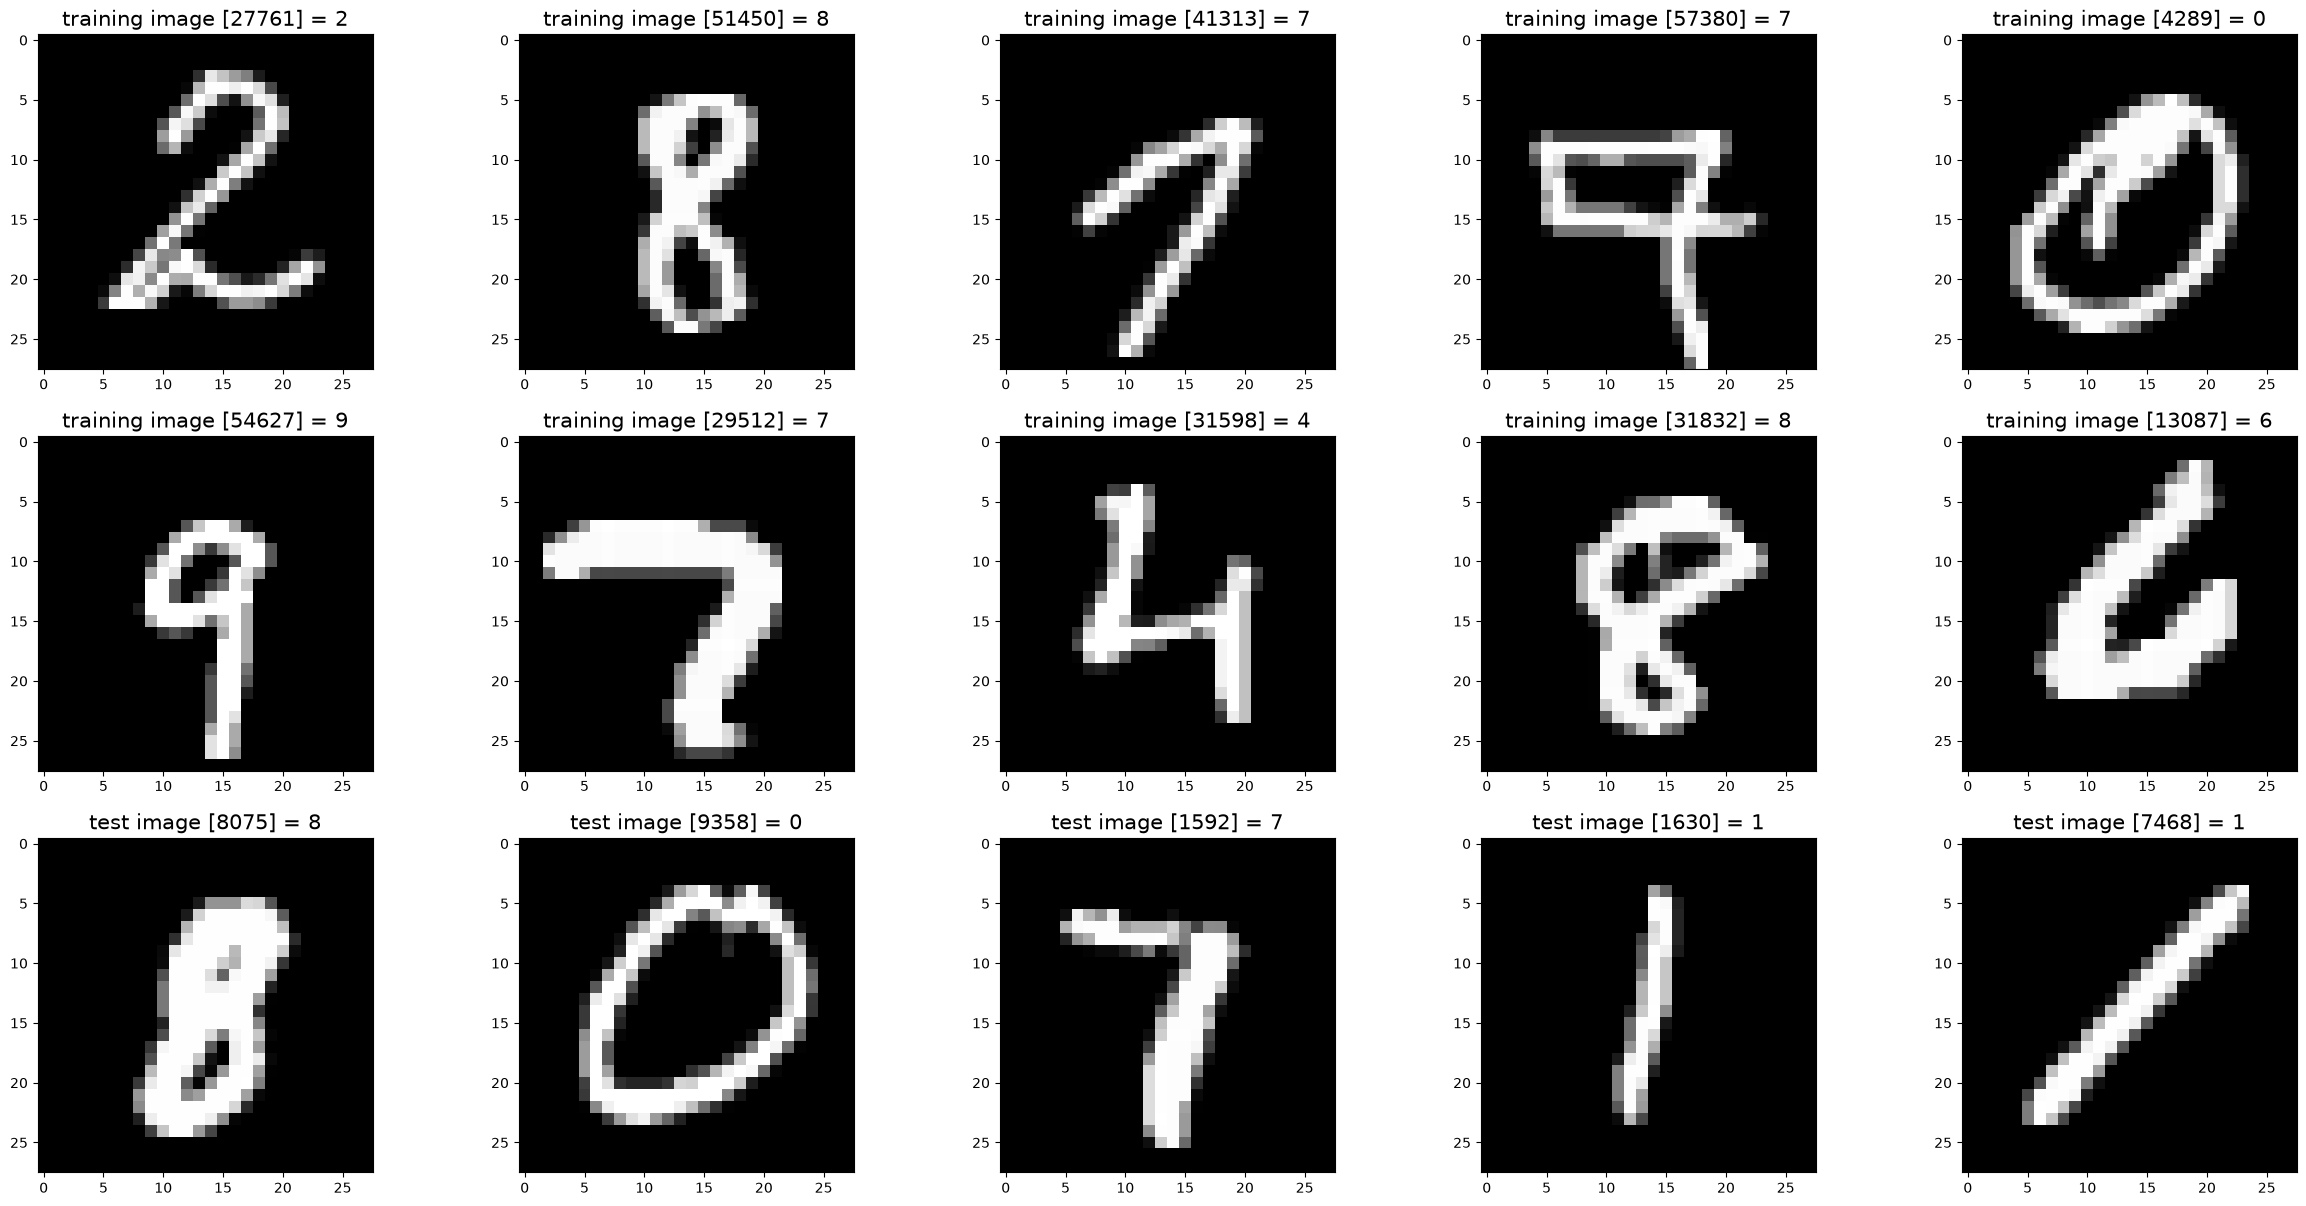

In [5]:
%matplotlib inline
import random
import matplotlib.pyplot as plt

#
# Set file paths based on added MNIST Datasets
#




#input_path = '/archive'
training_images_filepath = r"D:\Projects\CNNs\archive\train-images-idx3-ubyte\train-images-idx3-ubyte"
training_labels_filepath = r"D:\Projects\CNNs\archive\train-labels-idx1-ubyte\train-labels-idx1-ubyte"
test_images_filepath = r"D:\Projects\CNNs\archive\t10k-images-idx3-ubyte\t10k-images-idx3-ubyte"
test_labels_filepath = r"D:\Projects\CNNs\archive\t10k-labels-idx1-ubyte\t10k-labels-idx1-ubyte"

#
# Helper function to show a list of images with their relating titles
#
def show_images(images, title_texts):
    cols = 5
    rows = int(len(images)/cols) + 1
    plt.figure(figsize=(30,20))
    index = 1    
    for x in zip(images, title_texts):        
        image = x[0]        
        title_text = x[1]
        plt.subplot(rows, cols, index)        
        plt.imshow(image, cmap=plt.cm.gray)
        if (title_text != ''):
            plt.title(title_text, fontsize = 15);        
        index += 1

#
# Load MINST dataset
#
mnist_dataloader = MnistDataloader(training_images_filepath, training_labels_filepath, test_images_filepath, test_labels_filepath)
(x_train, y_train), (x_test, y_test) = mnist_dataloader.load_data()

#
# Show some random training and test images 
#
images_2_show = []
titles_2_show = []
for i in range(0, 10):
    r = random.randint(1, 60000)
    images_2_show.append(x_train[r])
    titles_2_show.append('training image [' + str(r) + '] = ' + str(y_train[r]))    

for i in range(0, 5):
    r = random.randint(1, 10000)
    images_2_show.append(x_test[r])        
    titles_2_show.append('test image [' + str(r) + '] = ' + str(y_test[r]))    

show_images(images_2_show, titles_2_show)


4


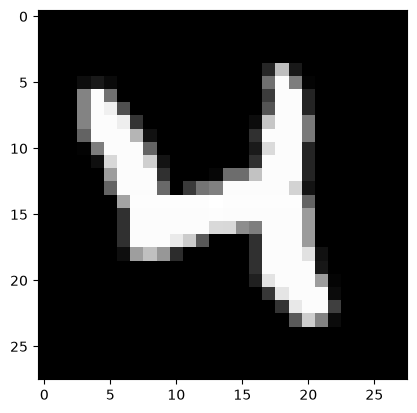

In [6]:

print(y_train[20])
plt.imshow(x_train[20],cmap = plt.cm.gray)

1
10000 10000 60000 60000
[array([0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0], dtype=uint8), array([0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0], dtype=uint8), array([0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0], dtype=uint8), array([  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
         0,   0, 166, 222,  55,   0,   0,   0,   0,   0,   0,   0,   0,
         0,   0], dtype=uint8), array([  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
         0,   0, 197, 254, 218,   5,   0,   0,   0,   0,   0,   0,   0,
         0,   0], dtype=uint8), array([  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
         0,  29, 249, 254, 254,   9,   0,   0,   0,   0,   0,   0,   0,
         0,   0], dtype=uint8), array([  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
         0,  45, 254, 254, 174,   

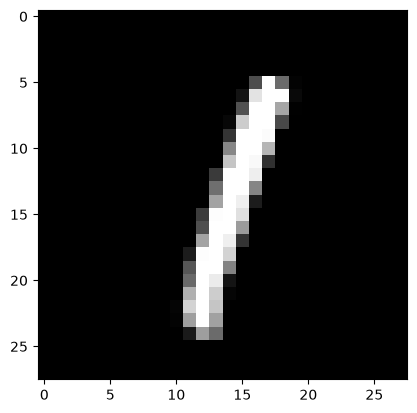

In [7]:
print(y_test[5])
plt.imshow(x_test[5],cmap = plt.cm.gray)
print(len(x_test),len(y_test),len(x_train),len(y_train))
print(x_train[24])

In [8]:
import numpy as np


for i in range(len(x_train)): 
    x_train[i] = np.array(x_train[i]) / 255
for i in range(len(x_test)):
    x_test[i] = np.array(x_test[i]) / 255



In [9]:
print(x_train[23].min())
print(x_train[23].max())
print(x_test[23].min())
print(x_test[23].max())

0.0
1.0
0.0
1.0


In [10]:
flattened_x_train = []
flattened_x_test = []
for z in range (len(x_train)):
    flattened_x_train.append((x_train[z]).reshape(-1))
for y in range(len(x_test)):
    flattened_x_test.append((x_test[y]).reshape(-1))

print(x_train[2].shape)
print(x_test[2].shape)
print(len(flattened_x_train[2]))
print(len(flattened_x_test[2]))

(28, 28)
(28, 28)
784
784


In [11]:
print(y_test[3])
new_y_train = []

for x in range(len(y_train)):
    new_y_train_sub = []
    for a in range(0,10):
        new_y_train_sub.append(0)
    #print(y_train[x])
    #print(x)
    new_y_train_sub[y_train[x]] = 1
    new_y_train.append(new_y_train_sub)


0


In [12]:
print(new_y_train)

[[0, 0, 0, 0, 0, 1, 0, 0, 0, 0], [1, 0, 0, 0, 0, 0, 0, 0, 0, 0], [0, 0, 0, 0, 1, 0, 0, 0, 0, 0], [0, 1, 0, 0, 0, 0, 0, 0, 0, 0], [0, 0, 0, 0, 0, 0, 0, 0, 0, 1], [0, 0, 1, 0, 0, 0, 0, 0, 0, 0], [0, 1, 0, 0, 0, 0, 0, 0, 0, 0], [0, 0, 0, 1, 0, 0, 0, 0, 0, 0], [0, 1, 0, 0, 0, 0, 0, 0, 0, 0], [0, 0, 0, 0, 1, 0, 0, 0, 0, 0], [0, 0, 0, 1, 0, 0, 0, 0, 0, 0], [0, 0, 0, 0, 0, 1, 0, 0, 0, 0], [0, 0, 0, 1, 0, 0, 0, 0, 0, 0], [0, 0, 0, 0, 0, 0, 1, 0, 0, 0], [0, 1, 0, 0, 0, 0, 0, 0, 0, 0], [0, 0, 0, 0, 0, 0, 0, 1, 0, 0], [0, 0, 1, 0, 0, 0, 0, 0, 0, 0], [0, 0, 0, 0, 0, 0, 0, 0, 1, 0], [0, 0, 0, 0, 0, 0, 1, 0, 0, 0], [0, 0, 0, 0, 0, 0, 0, 0, 0, 1], [0, 0, 0, 0, 1, 0, 0, 0, 0, 0], [1, 0, 0, 0, 0, 0, 0, 0, 0, 0], [0, 0, 0, 0, 0, 0, 0, 0, 0, 1], [0, 1, 0, 0, 0, 0, 0, 0, 0, 0], [0, 1, 0, 0, 0, 0, 0, 0, 0, 0], [0, 0, 1, 0, 0, 0, 0, 0, 0, 0], [0, 0, 0, 0, 1, 0, 0, 0, 0, 0], [0, 0, 0, 1, 0, 0, 0, 0, 0, 0], [0, 0, 1, 0, 0, 0, 0, 0, 0, 0], [0, 0, 0, 0, 0, 0, 0, 1, 0, 0], [0, 0, 0, 1, 0, 0, 0, 0, 0, 0], [0, 0, 

In [13]:
w1 = np.random.randn(784,128) * np.sqrt(2/784)
b1 = np.random.randn(1,128) 
print(w1)

[[ 0.0733642   0.01011689 -0.06988558 ... -0.03173416 -0.02162011
  -0.01845986]
 [-0.03947379  0.0144607  -0.07473086 ... -0.04324698 -0.00358052
  -0.07673496]
 [-0.05224064  0.0092199   0.03230681 ...  0.04946772 -0.06130491
  -0.07297609]
 ...
 [-0.00657824 -0.01924511  0.02070368 ... -0.03696195 -0.12249779
  -0.03995155]
 [-0.02958586  0.04892556  0.02933966 ...  0.01448585 -0.05330776
  -0.02607977]
 [ 0.04856112  0.04492002  0.0980806  ...  0.07191814  0.01950702
  -0.02633411]]


In [14]:
w2 = np.random.randn(128,10) * np.sqrt(2/128)
b2 = np.random.randn(1,10)

print(w2.shape,b2.shape,b1.shape,w1.shape)


(128, 10) (1, 10) (1, 128) (784, 128)


In [15]:
def ReLu(x):
    if x.all() < 0:
        return 0
    else:
        return x

def ReLu_derivative(x):
    if x.all() < 0:
        return 0
    else:
        return 1

def softmax(x):
    shifted_x = x -np.max(x,axis=-1,keepdims=True)
    exp_x = np.exp(shifted_x)

    sum_exp_x = np.sum(exp_x, axis = -1, keepdims=True)
    probabilities = exp_x / sum_exp_x
    
    return probabilities


In [37]:
def move_forward(x,w1,b1,w2,b2):
    z1 = x@w1 + b1
    a1 = ReLu(z1)
    z2 = a1@w2 + b2
    a2 = softmax(z2)

    #print(z1,a1,z2,a2)
    
    return z1,a1,z2,a2

In [17]:
def cross_entropy_loss(y_true, y_pred):
    
    loss = 0
    for i in range(len(y_true)):
        loss += -1*(y_true[i] * np.log(y_pred[i]))
    return loss

In [18]:
def update_parameters(w1,b1,w2,b2,dw1,db1,dw2,db2,learning_rate):
    w1 -= learning_rate * dw1
    b1 -= learning_rate * db1
    w2 -= learning_rate * dw2
    b2 -= learning_rate * db2

    return w1,b1,w2,b2

In [ ]:
learning_rate = 0.023
epochs = 2
batch_size = 100 # number of images checked before updating weights

In [ ]:
#requirements.txt readme 
#cross validation
#update git with data

In [20]:
### add backward propagation here ###
def backpropagation(x, predictons, z1, a1, w2,y_true):
        batch_size = x.shape[0]

    # Error at output layer
        dz2 = (predictions - y_true) / batch_size

    # Gradients for second layer
        dw2 = a1.T @ dz2
        db2 = np.sum(dz2, axis=0, keepdims=True)

    # Send error backwards through W2
        da1 = dz2 @ w2.T

    # Send error backwards through ReLU
        dz1 = da1 * ReLu_derivative(z1)

    # Gradients for first layer
        dw1 = x.T @ dz1
        db1 = np.sum(dz1, axis=0, keepdims=True)

        return dw1, db1, dw2, db2

In [44]:
for epoch in range(epochs):
    index = np.random.permutation(len(flattened_x_train))
    #print(index)
    x_shuffle = np.array(flattened_x_train)[index]
    
    y_shuffle = np.array(new_y_train)[index]
    epochs_loss = 0
    for start in range(0,len(flattened_x_train), batch_size):
        end = start + batch_size
        x_batch = x_shuffle[start:end]
        y_batch = y_shuffle[start:end]
        
        z1, a1, z2, predictions = move_forward(x_batch,w1,b1,w2,b2)
        loss = cross_entropy_loss(y_batch, predictions)


        
        dw1, db1, dw2, db2 = backpropagation(x_batch, predictions, z1, a1, w2,y_batch)
        w1,b1,w2,b2 = update_parameters(w1,b1,w2,b2,dw1,db1,dw2,db2,learning_rate)
        epochs_loss += loss
    epochs_loss /= len(flattened_x_train) / batch_size
    #print(epoch, epochs_loss)
   

In [35]:
print(w1,b1,w2,b2)

[[ 0.0733642   0.01011689 -0.06988558 ... -0.03173416 -0.02162011
  -0.01845986]
 [-0.03947379  0.0144607  -0.07473086 ... -0.04324698 -0.00358052
  -0.07673496]
 [-0.05224064  0.0092199   0.03230681 ...  0.04946772 -0.06130491
  -0.07297609]
 ...
 [-0.00657824 -0.01924511  0.02070368 ... -0.03696195 -0.12249779
  -0.03995155]
 [-0.02958586  0.04892556  0.02933966 ...  0.01448585 -0.05330776
  -0.02607977]
 [ 0.04856112  0.04492002  0.0980806  ...  0.07191814  0.01950702
  -0.02633411]] [[ 0.37700991 -1.09592755 -0.87946613 -0.5977584  -0.09715997 -0.38477262
  -0.43059519 -1.59162266  0.1066449  -0.70910151  0.94985215 -1.12771864
   0.01252808  0.15089961 -0.41758421  0.24664636  0.68490894  1.19003924
   0.02594347 -0.01053682  0.76504579 -0.19941015  0.33751679 -0.12813684
   1.33824715  1.47330889 -0.70034313  0.41397244 -1.51656618  1.04061884
   0.30219942 -0.26015234 -0.37133087 -0.59962685 -0.74176794  0.77819966
   0.42748194  0.95784675  0.48601351 -1.24014423  0.4400272  -0

1
1


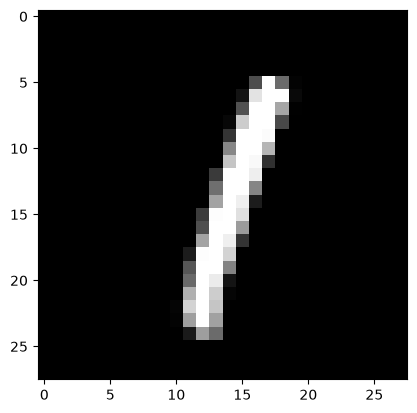

In [45]:
def predictions(x,w1,b1,w2,b2):
    z1,a1,z2,a2 = move_forward(x,w1,b1,w2,b2)
    return a2

predicted_label = (predictions(flattened_x_test,w1,b1,w2,b2))
plt.imshow(x_test[5],cmap = plt.cm.gray)
prediction_classes = np.argmax(predicted_label, axis=1)

print(prediction_classes[5])
print(y_test[5])

In [46]:
correct = 0
total = 0
for x in range(len(x_test)):
    total += 1
    if prediction_classes[x] == y_test[x]:
        correct += 1

print(correct/total)

0.9164
